# 2.5 — Regressão linear com `nn.MSELoss` e `optim.SGD`

## Objetivos

- Trocar a função de custo (loss) escrita à mão por `nn.MSELoss`.
- Trocar a atualização manual dos parâmetros por um otimizador do PyTorch, `optim.SGD`, com `zero_grad()` e `step()`.
- Verificar que o resultado é o mesmo do 2.4 e próximo da solução analítica.

O problema continua o mesmo: prever o comprimento da pétala da *Iris versicolor* a partir do comprimento da sépala, com a reta

$$\hat{y} = w_0 + w_1 x$$

em que $w_0$ é o bias e $w_1$ é o peso. Nos slides, $h_\theta(x) = \theta_0 + \theta_1 x$, com $w_0 = \theta_0$ e $w_1 = \theta_1$.

O que muda em relação ao 2.4:

| Etapa | 2.4 (autograd) | 2.5 (este notebook) |
|---|---|---|
| Modelo | `nn.Linear(2, 1, bias=False)` | igual |
| Função de custo | `torch.mean((y_pred - y_train)**2)` | `criterion = nn.MSELoss()` |
| Gradiente | `loss.backward()` | igual |
| Atualização | `with torch.no_grad(): model.weight -= lr * model.weight.grad` | `optimizer.step()` |
| Zerar o gradiente | `model.weight.grad.zero_()` | `optimizer.zero_grad()` |

Na figura do diagrama, o bloco "Custo" passa a ser o `criterion` e o bloco "Gradiente Descendente" passa a ser o `optimizer`. $\eta$ é a taxa de aprendizado (`lr`), $N$ é o número de amostras e $x_0$ é a entrada $x$.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

In [2]:
iris = load_iris()
# classe 1 (versicolor); colunas 0 e 2: comprimento da sépala e comprimento da pétala
data = iris.data[iris.target == 1, ::2]

x_train = data[:, 0:1].astype(np.float32)   # comprimento da sépala, shape (50, 1)
y_train = data[:, 1:2].astype(np.float32)   # comprimento da pétala, shape (50, 1)

n_samples = x_train.shape[0]
print('x_train.shape:', x_train.shape, x_train.dtype)
print('y_train.shape:', y_train.shape, y_train.dtype)

print('x_train[:5]:\n', x_train[:5])
print('y_train[:5]:\n', y_train[:5])

x_train.shape: (50, 1) float32
y_train.shape: (50, 1) float32
x_train[:5]:
 [[7. ]
 [6.4]
 [6.9]
 [5.5]
 [6.5]]
y_train[:5]:
 [[4.7]
 [4.5]
 [4.9]
 [4. ]
 [4.6]]


### Normalização (min-max, para o intervalo [0, 1])

In [3]:
x_train -= x_train.min()
x_train /= x_train.max()
y_train -= y_train.min()
y_train /= y_train.max()

### Coluna de uns e conversão para tensores

`x_train_bias` tem shape (50, 2): a coluna de uns multiplica $w_0$. Os dados são tensores comuns, sem `requires_grad`.

In [4]:
x_train_bias = np.hstack([np.ones(shape=(n_samples, 1)), x_train])

x_train_bias = torch.from_numpy(x_train_bias).float()
y_train = torch.from_numpy(y_train)
print('x_train_bias:', x_train_bias.shape, ' y_train:', y_train.shape)

x_train_bias: torch.Size([50, 2])  y_train: torch.Size([50, 1])


## Modelo

A mesma camada do 2.4: `model.weight` tem shape (1, 2) e guarda $[w_0, w_1]$.

In [5]:
model = nn.Linear(2, 1, bias=False)

### Inicialização dos parâmetros

Como no 2.4, uniforme em $[-0{,}1;\ 0{,}1]$.

In [6]:
nn.init.uniform_(model.weight, -0.1, 0.1)
model.weight

Parameter containing:
tensor([[-0.0480, -0.0267]], requires_grad=True)

### Testando o predict da rede

In [7]:
model(torch.ones((5, 2)))

tensor([[-0.0747],
        [-0.0747],
        [-0.0747],
        [-0.0747],
        [-0.0747]], grad_fn=<MmBackward0>)

## Treinamento

### Função de custo e otimizador

- `nn.MSELoss()` cria um objeto que calcula $\frac{1}{M}\sum_{i=1}^{M}(\hat{y}^{(i)} - y^{(i)})^2$, o mesmo MSE do 2.4 (a média é o padrão, `reduction='mean'`). Chama-se `criterion(previsão, alvo)`, nessa ordem.
- `optim.SGD(model.parameters(), lr=lr)` cria o otimizador de gradiente descendente. `model.parameters()` entrega ao otimizador os tensores que ele vai atualizar; aqui, só `model.weight`.
    - `optimizer.zero_grad()` zera o gradiente de todos esses parâmetros;
    - `optimizer.step()` aplica $w \leftarrow w - \text{lr} \cdot \nabla_w J$ usando o `.grad` calculado por `loss.backward()`.

`criterion` e `optimizer` são nomes de variáveis usados por convenção; `nn.MSELoss` e `optim.SGD` são do PyTorch.

In [8]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

Verificação: com os parâmetros iniciais, `criterion` dá o mesmo valor do custo escrito à mão no 2.4.

In [9]:
with torch.no_grad():
    y_pred = model(x_train_bias)
    print('nn.MSELoss:  ', criterion(y_pred, y_train).item())
    print('torch.mean:  ', torch.mean((y_pred - y_train) ** 2).item())

nn.MSELoss:   0.48845168948173523
torch.mean:   0.48845168948173523


### Laço de treinamento

Cada época tem os mesmos passos do 2.4: forward → custo → `zero_grad()` → `backward()` → `step()`. A ordem importa: o gradiente é zerado antes do `backward()`, que o recalcula, e o `step()` vem depois, para usar o gradiente novo.

As listas `w0_list` e `w1_list` guardam os parâmetros a cada época (antes da atualização), para o Exercício 2.

In [10]:
n_epochs = 120
losses = []
w0_list = []
w1_list = []

for epoch in range(n_epochs):
    # forward: previsão
    y_pred = model(x_train_bias)

    w0_list.append(model.weight[0, 0].item())
    w1_list.append(model.weight[0, 1].item())

    # função de custo
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    optimizer.zero_grad()   # zera os gradientes acumulados
    loss.backward()         # autograd: calcula model.weight.grad
    optimizer.step()        # gradiente descendente: w <- w - lr * grad

    losses.append(loss.item())
    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], loss: {loss.item():.6f}')

Epoch[20/120], loss: 0.024990
Epoch[40/120], loss: 0.022381
Epoch[60/120], loss: 0.021554
Epoch[80/120], loss: 0.021291
Epoch[100/120], loss: 0.021208
Epoch[120/120], loss: 0.021182


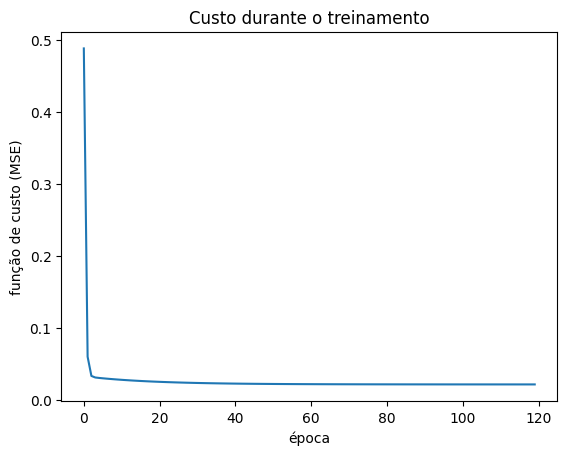

In [11]:
plt.plot(losses)
plt.xlabel('época')
plt.ylabel('função de custo (MSE)')
plt.title('Custo durante o treinamento')
plt.show()

## Avaliação

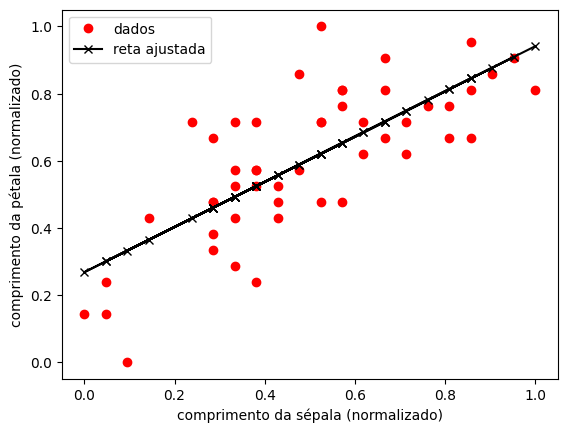

In [12]:
with torch.no_grad():
    y_pred = model(x_train_bias)

plt.plot(x_train, y_train.numpy(), 'ro', label='dados')
plt.plot(x_train, y_pred.numpy(), 'kx-', label='reta ajustada')
plt.xlabel('comprimento da sépala (normalizado)')
plt.ylabel('comprimento da pétala (normalizado)')
plt.legend()
plt.show()

### Comparação com a solução analítica

A equação normal $w^{*T} = (X^T X)^{-1} X^T y$ (2.2 e 2.4) dá os parâmetros ótimos; o modelo treinado deve ficar próximo.

In [13]:
x_bias_t = x_train_bias.t()
w_opt = torch.inverse(x_bias_t.mm(x_train_bias)).mm(x_bias_t).mm(y_train)
print('w_opt (analítico):', w_opt.t())
print('w treinado:       ', model.weight.detach())

w_opt (analítico): tensor([[0.2613, 0.6865]])
w treinado:        tensor([[0.2685, 0.6726]])


## Exercícios

### Exercício 1 — Custo final com `criterion`

Calcule o valor da função de custo (MSE) depois da rede treinada, usando o `criterion` do laço de treinamento, e guarde o resultado em `loss`. Use `torch.no_grad()`, porque aqui só avaliamos o modelo.

In [14]:
with torch.no_grad():
    loss = criterion(model(x_train_bias), y_train)
print(f'MSE final: {loss.item():.6f}')

MSE final: 0.021181


In [15]:
# comparação com o último custo do laço e com o MSE dos parâmetros ótimos
with torch.no_grad():
    mse_opt = criterion(x_train_bias.mm(w_opt), y_train)
print(f'MSE do modelo treinado (criterion):  {loss.item():.8f}')
print(f'último valor do laço (losses[-1]):    {losses[-1]:.8f}')
print(f'MSE da solução analítica:             {mse_opt.item():.8f}')

MSE do modelo treinado (criterion):  0.02118101
último valor do laço (losses[-1]):    0.02118169
MSE da solução analítica:             0.02116942


O custo final é praticamente o da solução analítica (0,021181 contra 0,021169: diferença de cerca de $1{,}2 \times 10^{-5}$). O valor de `loss` calculado aqui é um pouco menor que `losses[-1]`, porque `losses[-1]` foi calculado no forward da última época, *antes* do último `optimizer.step()`; já o `loss` do exercício usa os parâmetros *depois* dessa atualização. É o mesmo efeito observado no Exercício 2 do 2.4. Aqui a diferença é maior que no 2.4 (cerca de $7 \times 10^{-7}$) porque `lr = 0,3` converge mais devagar que `lr = 0,5`.

### Exercício 2 — Trajetória dos parâmetros

Como no Exercício 3 do 2.4, faça um scatter plot com setas mostrando a evolução de $(w_0, w_1)$ durante o treinamento, usando as listas `w0_list` e `w1_list` já preenchidas no laço. Marque o ponto inicial e o ótimo analítico `w_opt`. Compare com o gráfico do 2.4: o caminho tem a mesma forma?

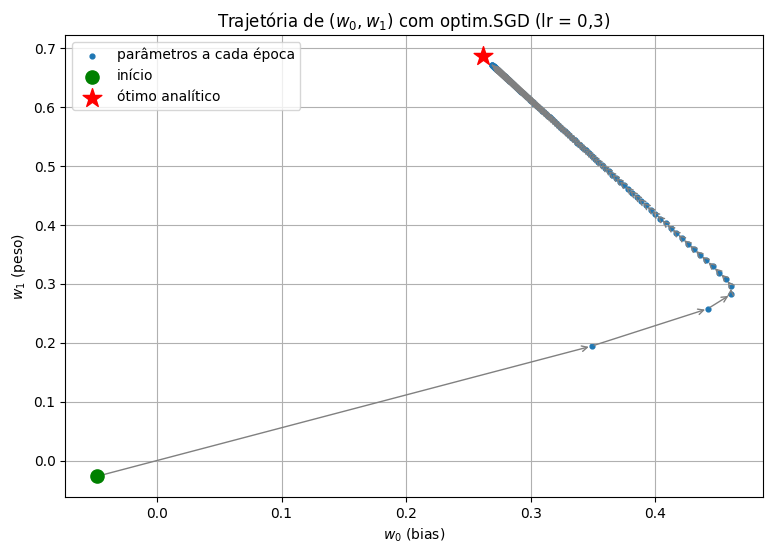

In [16]:
w0_opt, w1_opt = w_opt[0, 0].item(), w_opt[1, 0].item()

def plot_trajetoria(ax, w0s, w1s, titulo):
    ax.scatter(w0s, w1s, s=12, label='parâmetros a cada época')
    for i in range(1, len(w0s)):
        ax.annotate('', xy=(w0s[i], w1s[i]), xytext=(w0s[i - 1], w1s[i - 1]),
                    arrowprops=dict(arrowstyle='->', color='gray'))
    ax.scatter(w0s[0], w1s[0], c='green', s=90, label='início', zorder=3)
    ax.scatter(w0_opt, w1_opt, c='red', s=200, marker='*', label='ótimo analítico', zorder=4)
    ax.set_xlabel('$w_0$ (bias)')
    ax.set_ylabel('$w_1$ (peso)')
    ax.set_title(titulo)
    ax.legend()
    ax.grid(True)

fig, ax = plt.subplots(figsize=(9, 6))
plot_trajetoria(ax, w0_list, w1_list, 'Trajetória de $(w_0, w_1)$ com optim.SGD (lr = 0,3)')
plt.show()

#### Comparação com o 2.4

Para comparar de forma objetiva, abaixo reproduzimos o laço **manual** do 2.4 (`loss.backward()` + atualização com `torch.no_grad()`), partindo exatamente dos mesmos pesos iniciais:

1. com a mesma taxa de aprendizado deste notebook (`lr = 0,3`), para verificar se o `optim.SGD` dá o mesmo caminho;
2. com a taxa original do 2.4 (`lr = 0,5`, 100 épocas), para ver o efeito da mudança de `lr`.

maior diferença entre as trajetórias (manual × optim.SGD, lr=0.3): 0.00e+00


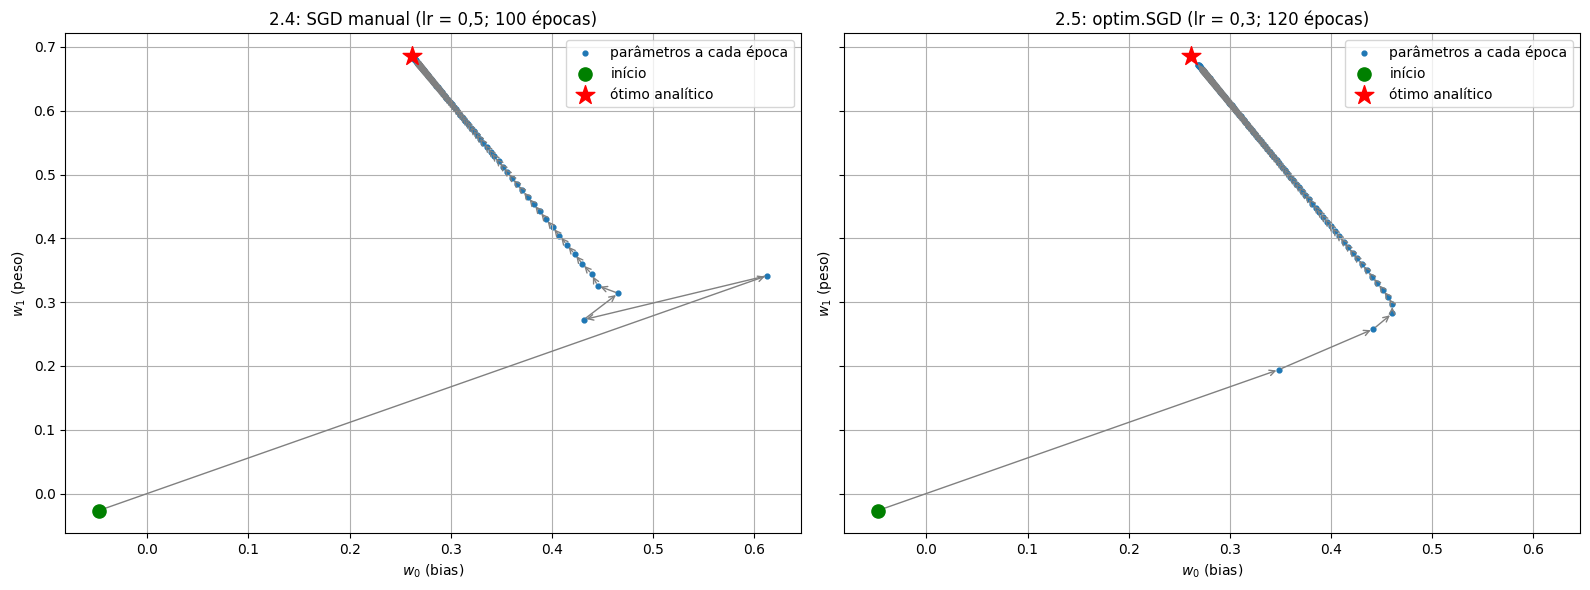

distância final ao ótimo - 2.4 (lr=0.5): 0.00411
distância final ao ótimo - 2.5 (lr=0.3): 0.01613


In [17]:
def treina_manual(w_ini, lr, n_epochs):
    """Laço do 2.4: backward + atualização manual dentro de torch.no_grad()."""
    m = nn.Linear(2, 1, bias=False)
    with torch.no_grad():
        m.weight.copy_(torch.tensor([w_ini]))
    w0s, w1s = [], []
    for _ in range(n_epochs):
        w0s.append(m.weight[0, 0].item()); w1s.append(m.weight[0, 1].item())
        loss = torch.mean((m(x_train_bias) - y_train) ** 2)
        loss.backward()
        with torch.no_grad():
            m.weight -= lr * m.weight.grad
        m.weight.grad.zero_()
    return w0s, w1s

w_ini = [w0_list[0], w1_list[0]]   # mesmos pesos iniciais

# 1) laço manual (2.4) com lr = 0.3 e 120 épocas, igual ao deste notebook
w0_man, w1_man = treina_manual(w_ini, lr=0.3, n_epochs=120)
dif = max(np.abs(np.array(w0_man) - w0_list).max(), np.abs(np.array(w1_man) - w1_list).max())
print(f'maior diferença entre as trajetórias (manual × optim.SGD, lr=0.3): {dif:.2e}')

# 2) laço do 2.4 original: lr = 0.5 e 100 épocas
w0_24, w1_24 = treina_manual(w_ini, lr=0.5, n_epochs=100)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
plot_trajetoria(axes[0], w0_24, w1_24, '2.4: SGD manual (lr = 0,5; 100 épocas)')
plot_trajetoria(axes[1], w0_list, w1_list, '2.5: optim.SGD (lr = 0,3; 120 épocas)')
plt.tight_layout()
plt.show()

print('distância final ao ótimo - 2.4 (lr=0.5): {:.5f}'.format(np.hypot(w0_24[-1] - w0_opt, w1_24[-1] - w1_opt)))
print('distância final ao ótimo - 2.5 (lr=0.3): {:.5f}'.format(np.hypot(w0_list[-1] - w0_opt, w1_list[-1] - w1_opt)))

**Resposta:** sim, o caminho tem a mesma forma. A verificação numérica mostra que, com a mesma taxa de aprendizado e os mesmos pesos iniciais, a trajetória do `optim.SGD` é **idêntica** à do laço manual do 2.4 (a maior diferença impressa acima é exatamente 0): o otimizador não muda o algoritmo, só empacota `zero_grad()` + atualização (`optimizer.step()` faz $w \leftarrow w - \text{lr}\cdot\nabla_w J$). Em ambos os gráficos o caminho parte de perto da origem e vai em direção ao ótimo analítico (estrela vermelha), com passos longos no início (gradiente grande) e cada vez menores perto do mínimo, formando uma curva e não uma reta.

As diferenças visíveis entre os dois gráficos vêm só dos hiperparâmetros: o 2.4 usa `lr = 0,5` e 100 épocas, e o 2.5 usa `lr = 0,3` e 120 épocas. Com a taxa menor, os passos são mais curtos, então os pontos ficam mais juntos e o caminho é percorrido mais devagar; por isso, mesmo com 20 épocas a mais, o 2.5 termina um pouco mais longe do ótimo do que o 2.4 (veja as distâncias finais impressas acima). O destino é o mesmo: o ótimo analítico.

## Aprendizados

- `nn.MSELoss()` calcula o mesmo MSE escrito à mão no 2.4; chama-se `criterion(previsão, alvo)`.
- `optim.SGD(model.parameters(), lr=lr)` recebe os parâmetros a atualizar; `zero_grad()` zera os gradientes e `step()` aplica o passo do gradiente descendente.
- A ordem em cada época é forward → custo → `zero_grad()` → `backward()` → `step()`.
- O otimizador não muda o algoritmo: a trajetória e os parâmetros finais são os mesmos do gradiente descendente manual.